# Resume Classification with a Vanilla LSTM (Overfitting Baseline)

project pipeline:

0. Config & imports
1. Preprocessing & stratified split
2. Dataset & DataLoaders
3. Model (Vanilla LSTM)
4. Training (deliberate overfitting, no regularization)
5. Evaluation & artifacts


## 0. Config & Imports

In [19]:
import os, re, json, time, random
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, accuracy_score)

In [20]:
# ───────── CONFIG ─────────
class config:
    SEED = 42

    # Paths (relative to the notebook's working directory)
    _cwd               = os.getcwd()
    BASE_DIR           = os.path.dirname(_cwd) if os.path.basename(_cwd) == "notebooks" else _cwd
    RAW_DATA_PATH      = os.path.join(BASE_DIR, "data", "raw", "resume.csv")
    PROCESSED_DIR      = os.path.join(BASE_DIR, "data", "preprocessed")
    MODELS_DIR         = os.path.join(BASE_DIR, "models")
    
    TRAIN_PATH         = os.path.join(PROCESSED_DIR, "train.csv")
    VAL_PATH           = os.path.join(PROCESSED_DIR, "val.csv")
    TEST_PATH          = os.path.join(PROCESSED_DIR, "test.csv")
    VOCAB_PATH         = os.path.join(PROCESSED_DIR, "vocab.json")
    LABEL_ENCODER_PATH = os.path.join(PROCESSED_DIR, "label_encoder.json")
    
    CHECKPOINT_PATH    = os.path.join(MODELS_DIR, "vanilla_lstm_overfit.pt")
    HISTORY_PATH       = os.path.join(MODELS_DIR, "history.json")

    # Preprocessing
    MAX_LEN     = 400
    VOCAB_SIZE  = 15_000
    TRAIN_RATIO = 0.70
    VAL_RATIO   = 0.15
    TEST_RATIO  = 0.15

    # Model
    EMBEDDING_DIM = 128
    HIDDEN_DIM    = 256
    NUM_LAYERS    = 2
    DROPOUT       = 0.0      # intentionally 0 -> induces overfitting
    NUM_CLASSES   = 24

    # Training
    BATCH_SIZE    = 64
    LEARNING_RATE = 1e-3
    NUM_EPOCHS    = 12
    WEIGHT_DECAY  = 0.0      # intentionally 0 -> induces overfitting

    # Special tokens
    PAD_TOKEN, UNK_TOKEN = "<PAD>", "<UNK>"
    PAD_IDX, UNK_IDX     = 0, 1

os.makedirs(config.PROCESSED_DIR, exist_ok=True)
os.makedirs(config.MODELS_DIR, exist_ok=True)

## 1. Preprocessing & Stratified Split

In [21]:
def clean_text(text: str) -> str:
    """Lowercase, normalise whitespace, strip noisy characters."""
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = text.replace("\u2013", "-").replace("\u2014", "-").replace("\uff0d", "-")
    text = text.replace("\u2022", " ").replace("\u2019", "'").replace("\u00e2", "")
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"[^a-z0-9 .,'&/+#-]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def tokenize(text: str) -> list[str]:
    return text.split()


def stratified_split(df: pd.DataFrame, seed: int = config.SEED):
    """Per-category split preserving class balance."""
    random.seed(seed)
    train_rows, val_rows, test_rows = [], [], []
    for category, group in df.groupby("Category"):
        group = group.sample(frac=1, random_state=seed).reset_index(drop=True)
        n = len(group)
        n_train = int(n * config.TRAIN_RATIO)
        n_val   = int(n * config.VAL_RATIO)
        train_rows.append(group.iloc[:n_train])
        val_rows.append(group.iloc[n_train:n_train + n_val])
        test_rows.append(group.iloc[n_train + n_val:])
    shuffle = lambda rows: pd.concat(rows).sample(frac=1, random_state=seed).reset_index(drop=True)
    return shuffle(train_rows), shuffle(val_rows), shuffle(test_rows)


def build_vocab(texts: list[str], max_vocab_size: int = config.VOCAB_SIZE) -> dict:
    """token -> index (0=<PAD>, 1=<UNK>, rest by frequency)."""
    counter = Counter()
    for text in texts:
        counter.update(tokenize(text))
    vocab = {config.PAD_TOKEN: config.PAD_IDX, config.UNK_TOKEN: config.UNK_IDX}
    for idx, (token, _) in enumerate(counter.most_common(max_vocab_size - 2), start=2):
        vocab[token] = idx
    return vocab


def build_label_encoder(categories: list[str]) -> dict:
    return {cat: idx for idx, cat in enumerate(sorted(set(categories)))}

In [22]:
df = pd.read_csv(config.RAW_DATA_PATH)
print("Raw shape:", df.shape)

df = df.dropna(subset=["Resume_str"]).reset_index(drop=True)
print("After dropping missing:", df.shape)

df["clean_text"] = df["Resume_str"].apply(clean_text)
df["token_count"] = df["clean_text"].apply(lambda t: len(tokenize(t)))
print(f"Token counts -> min: {df['token_count'].min()}  median: {int(df['token_count'].median())}  max: {df['token_count'].max()}")
print("Resumes with < 20 tokens:", (df["token_count"] < 20).sum())

# Trim to MAX_LEN
df["clean_text"] = df["clean_text"].apply(lambda t: " ".join(tokenize(t)[:config.MAX_LEN]))

train_df, val_df, test_df = stratified_split(df[["ID", "clean_text", "Category"]])
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

for cat in sorted(df["Category"].unique()):
    print(f"  {cat:<25} total={(df['Category']==cat).sum():3d}  "
          f"train={(train_df['Category']==cat).sum():3d}  "
          f"val={(val_df['Category']==cat).sum():2d}  "
          f"test={(test_df['Category']==cat).sum():2d}")

train_df.to_csv(config.TRAIN_PATH, index=False)
val_df.to_csv(config.VAL_PATH, index=False)
test_df.to_csv(config.TEST_PATH, index=False)

# Vocab from TRAIN ONLY
vocab = build_vocab(train_df["clean_text"].tolist())
label_encoder = build_label_encoder(df["Category"].tolist())
print("Vocab size:", len(vocab), "| Classes:", len(label_encoder))

with open(config.VOCAB_PATH, "w", encoding="utf-8") as f:
    json.dump(vocab, f, indent=2)
with open(config.LABEL_ENCODER_PATH, "w", encoding="utf-8") as f:
    json.dump(label_encoder, f, indent=2)

Raw shape: (2484, 4)
After dropping missing: (2484, 4)
Token counts -> min: 0  median: 755  max: 5209
Resumes with < 20 tokens: 1
Train: 1728 | Val: 362 | Test: 394
  ACCOUNTANT                total=118  train= 82  val=17  test=19
  ADVOCATE                  total=118  train= 82  val=17  test=19
  AGRICULTURE               total= 63  train= 44  val= 9  test=10
  APPAREL                   total= 97  train= 67  val=14  test=16
  ARTS                      total=103  train= 72  val=15  test=16
  AUTOMOBILE                total= 36  train= 25  val= 5  test= 6
  AVIATION                  total=117  train= 81  val=17  test=19
  BANKING                   total=115  train= 80  val=17  test=18
  BPO                       total= 22  train= 15  val= 3  test= 4
  BUSINESS-DEVELOPMENT      total=120  train= 84  val=18  test=18
  CHEF                      total=118  train= 82  val=17  test=19
  CONSTRUCTION              total=112  train= 78  val=16  test=18
  CONSULTANT                total=115  trai

## 2. Dataset & DataLoaders

In [23]:
def load_vocab(path=config.VOCAB_PATH) -> dict:
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

def load_label_encoder(path=config.LABEL_ENCODER_PATH) -> dict:
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


class ResumeDataset(Dataset):
    """Cleaned text -> padded/truncated token-index tensor; category -> label index."""

    def __init__(self, csv_path, vocab, label_encoder, max_len=config.MAX_LEN):
        self.df = pd.read_csv(csv_path)
        self.df["clean_text"] = self.df["clean_text"].fillna("")
        self.vocab = vocab
        self.label_encoder = label_encoder
        self.max_len = max_len
        self.pad_idx = vocab.get(config.PAD_TOKEN, config.PAD_IDX)
        self.unk_idx = vocab.get(config.UNK_TOKEN, config.UNK_IDX)

    def __len__(self):
        return len(self.df)

    def text_to_indices(self, text: str) -> list[int]:
        indices = [self.vocab.get(tok, self.unk_idx) for tok in text.split()]
        if len(indices) >= self.max_len:
            return indices[: self.max_len]
        return indices + [self.pad_idx] * (self.max_len - len(indices))

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        x = torch.tensor(self.text_to_indices(str(row["clean_text"])), dtype=torch.long)
        y = torch.tensor(self.label_encoder[row["Category"]], dtype=torch.long)
        return x, y


def get_dataloaders(batch_size=config.BATCH_SIZE, num_workers=0):
    vocab = load_vocab()
    label_encoder = load_label_encoder()
    train_ds = ResumeDataset(config.TRAIN_PATH, vocab, label_encoder)
    val_ds   = ResumeDataset(config.VAL_PATH,   vocab, label_encoder)
    test_ds  = ResumeDataset(config.TEST_PATH,  vocab, label_encoder)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,  num_workers=num_workers)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=num_workers)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=num_workers)
    return train_loader, val_loader, test_loader, vocab, label_encoder

In [24]:
train_loader, val_loader, test_loader, vocab, label_encoder = get_dataloaders()
print(f"Vocab size: {len(vocab)} | Classes: {len(label_encoder)}")
print(f"Train: {len(train_loader)} batches ({len(train_loader.dataset)} samples)")
print(f"Val:   {len(val_loader)} batches ({len(val_loader.dataset)} samples)")
print(f"Test:  {len(test_loader)} batches ({len(test_loader.dataset)} samples)")

x_batch, y_batch = next(iter(train_loader))
inv_labels = {v: k for k, v in label_encoder.items()}
print("x:", x_batch.shape, x_batch.dtype, "| y:", y_batch.shape, y_batch.dtype)
print("Sample label:", y_batch[0].item(), "->", inv_labels[y_batch[0].item()])

Vocab size: 15000 | Classes: 24
Train: 27 batches (1728 samples)
Val:   6 batches (362 samples)
Test:  7 batches (394 samples)
x: torch.Size([64, 400]) torch.int64 | y: torch.Size([64]) torch.int64
Sample label: 2 -> AGRICULTURE


## 3. Model: Vanilla LSTM Classifier

In [25]:
class VanillaLSTMClassifier(nn.Module):
    """Embedding -> LSTM -> last hidden state -> Linear."""

    def __init__(self, vocab_size=config.VOCAB_SIZE, embedding_dim=config.EMBEDDING_DIM,
                 hidden_dim=config.HIDDEN_DIM, num_layers=config.NUM_LAYERS,
                 num_classes=config.NUM_CLASSES, dropout=config.DROPOUT, pad_idx=config.PAD_IDX):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, num_layers=num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0, bidirectional=False)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        embedded = self.embedding(x)              # (B, T, E)
        _, (h_n, _) = self.lstm(embedded)         # h_n: (layers, B, H)
        return self.fc(h_n[-1])                   # (B, num_classes)

    def count_parameters(self):
        total = sum(p.numel() for p in self.parameters())
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        return {"total": total, "trainable": trainable}


def build_model(vocab_size=config.VOCAB_SIZE):
    return VanillaLSTMClassifier(vocab_size=vocab_size)

In [26]:
model = build_model(vocab_size=len(vocab))
print(model)
print(model.count_parameters())

with torch.no_grad():
    dummy = torch.randint(0, len(vocab), (config.BATCH_SIZE, config.MAX_LEN))
    assert model(dummy).shape == (config.BATCH_SIZE, config.NUM_CLASSES)
print("Forward-pass check passed.")

VanillaLSTMClassifier(
  (embedding): Embedding(15000, 128, padding_idx=0)
  (lstm): LSTM(128, 256, num_layers=2, batch_first=True)
  (fc): Linear(in_features=256, out_features=24, bias=True)
)
{'total': 2847768, 'trainable': 2847768}
Forward-pass check passed.


## 4. Training (Deliberate Overfitting Experiment)

In [27]:
def set_seed(seed=config.SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for x, y in dataloader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * x.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        total += y.size(0)
    return running_loss / total, correct / total


def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in dataloader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = criterion(logits, y)
            running_loss += loss.item() * x.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            total += y.size(0)
    return running_loss / total, correct / total

In [28]:
set_seed(config.SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device} | Epochs: {config.NUM_EPOCHS} | Batch: {config.BATCH_SIZE} | "
      f"LR: {config.LEARNING_RATE} | Dropout: {config.DROPOUT} | WD: {config.WEIGHT_DECAY}")

model = build_model(vocab_size=len(vocab)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=config.LEARNING_RATE,
                             weight_decay=config.WEIGHT_DECAY)

history = {k: [] for k in ["epoch", "train_loss", "train_acc", "val_loss", "val_acc", "epoch_time_sec"]}
best_val_loss, best_val_epoch = float("inf"), -1
start_total = time.time()

print(f"{'Epoch':<10} | {'Train Loss':<12} | {'Train Acc':<11} | {'Val Loss':<12} | {'Val Acc':<11} | Time")
print("-" * 75)
for epoch in range(1, config.NUM_EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    va_loss, va_acc = evaluate(model, val_loader, criterion, device)
    elapsed = time.time() - t0

    for k, v in zip(history.keys(), [epoch, tr_loss, tr_acc, va_loss, va_acc, elapsed]):
        history[k].append(v)
    if va_loss < best_val_loss:
        best_val_loss, best_val_epoch = va_loss, epoch

    print(f"Epoch [{epoch:02d}/{config.NUM_EPOCHS:02d}] | {tr_loss:10.4f}   | {tr_acc*100:8.2f}%   | "
          f"{va_loss:10.4f}   | {va_acc*100:8.2f}%   | {elapsed:5.1f}s")

print("-" * 75)
print(f"Total training time: {(time.time() - start_total)/60:.2f} min")

Device: cpu | Epochs: 12 | Batch: 64 | LR: 0.001 | Dropout: 0.0 | WD: 0.0
Epoch      | Train Loss   | Train Acc   | Val Loss     | Val Acc     | Time
---------------------------------------------------------------------------
Epoch [01/12] |     3.1645   |     3.94%   |     3.1330   |     6.91%   |  19.8s
Epoch [02/12] |     3.0793   |     9.72%   |     3.1269   |     7.18%   |  20.8s
Epoch [03/12] |     2.8970   |    16.78%   |     3.1419   |     8.29%   |  21.6s
Epoch [04/12] |     2.5702   |    25.17%   |     3.3130   |    11.05%   |  21.7s
Epoch [05/12] |     2.0819   |    41.26%   |     3.4274   |     8.84%   |  21.8s
Epoch [06/12] |     1.5454   |    56.89%   |     3.6854   |     8.84%   |  21.1s
Epoch [07/12] |     1.0821   |    70.20%   |     4.0195   |     8.56%   |  21.7s
Epoch [08/12] |     0.7399   |    81.25%   |     4.4205   |     9.39%   |  22.3s
Epoch [09/12] |     0.4656   |    88.72%   |     4.7718   |     9.12%   |  20.8s
Epoch [10/12] |     0.3535   |    90.45%   | 

In [29]:
checkpoint = {
    "epoch": config.NUM_EPOCHS,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "final_train_loss": history["train_loss"][-1],
    "final_train_acc":  history["train_acc"][-1],
    "final_val_loss":   history["val_loss"][-1],
    "final_val_acc":    history["val_acc"][-1],
    "best_val_loss": best_val_loss,
    "best_val_epoch": best_val_epoch,
    "vocab_size": len(vocab),
    "num_classes": len(label_encoder),
    "config": {k: getattr(config, k) for k in
               ["EMBEDDING_DIM","HIDDEN_DIM","NUM_LAYERS","DROPOUT","LEARNING_RATE",
                "WEIGHT_DECAY","BATCH_SIZE","MAX_LEN","SEED"]},
}
torch.save(checkpoint, config.CHECKPOINT_PATH)
with open(config.HISTORY_PATH, "w", encoding="utf-8") as f:
    json.dump(history, f, indent=2)

gap = (history["train_acc"][-1] - history["val_acc"][-1]) * 100
print("SUMMARY")
print(f"  Final Train Acc: {history['train_acc'][-1]*100:.2f}%")
print(f"  Final Val Acc:   {history['val_acc'][-1]*100:.2f}%")
print(f"  Generalization gap: {gap:.2f}%")
print(f"  Final Train Loss: {history['train_loss'][-1]:.4f}")
print(f"  Lowest Val Loss:  {best_val_loss:.4f} (epoch {best_val_epoch})")
print(f"  Final Val Loss:   {history['val_loss'][-1]:.4f} (+{history['val_loss'][-1]-best_val_loss:.4f})")

SUMMARY
  Final Train Acc: 91.67%
  Final Val Acc:   8.29%
  Generalization gap: 83.38%
  Final Train Loss: 0.2841
  Lowest Val Loss:  3.1269 (epoch 2)
  Final Val Loss:   5.2308 (+2.1039)


## 5. Evaluation & Artifacts

In [30]:
def plot_training_curves(history: dict, save_path: str):
    epochs = history["epoch"]
    train_acc = [a * 100 for a in history["train_acc"]]
    val_acc   = [a * 100 for a in history["val_acc"]]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(epochs, history["train_loss"], label="Train Loss", color="#1f77b4", linewidth=2)
    ax1.plot(epochs, history["val_loss"], label="Validation Loss", color="#ff7f0e", linewidth=2, linestyle="--")
    best = int(np.argmin(history["val_loss"]))
    ax1.axvline(x=epochs[best], color="gray", linestyle=":", label=f"Min Val Loss (Ep {epochs[best]})")
    ax1.set_title("Cross-Entropy Loss (Overfitting Divergence)", fontsize=13, fontweight="bold")
    ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.grid(True, alpha=0.3); ax1.legend()

    ax2.plot(epochs, train_acc, label="Train Accuracy", color="#2ca02c", linewidth=2)
    ax2.plot(epochs, val_acc, label="Validation Accuracy", color="#d62728", linewidth=2, linestyle="--")
    ax2.set_title(f"Accuracy (Generalization Gap: {train_acc[-1]-val_acc[-1]:.1f}%)", fontsize=13, fontweight="bold")
    ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy (%)"); ax2.grid(True, alpha=0.3); ax2.legend()

    plt.tight_layout()
    plt.savefig(save_path, dpi=200)
    plt.show()
    print(f"[Saved] {save_path}")


def plot_confusion_matrix(cm, labels, save_path):
    cm_norm = cm.astype("float") / (cm.sum(axis=1)[:, np.newaxis] + 1e-9)
    fig, ax = plt.subplots(figsize=(13, 11))
    im = ax.imshow(cm_norm, interpolation="nearest", cmap="Blues")
    plt.colorbar(im, fraction=0.046, pad=0.04)
    ax.set_xticks(np.arange(len(labels))); ax.set_yticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=90, fontsize=8); ax.set_yticklabels(labels, fontsize=8)
    ax.set_title("Normalized Confusion Matrix (Test Set)", fontsize=13, fontweight="bold")
    ax.set_xlabel("Predicted Label"); ax.set_ylabel("True Label")
    plt.tight_layout()
    plt.savefig(save_path, dpi=200)
    plt.show()
    print(f"[Saved] {save_path}")

In [31]:
# Reload the saved checkpoint (mirrors the standalone evaluate script)
class_names = [k for k, _ in sorted(label_encoder.items(), key=lambda kv: kv[1])]

checkpoint = torch.load(config.CHECKPOINT_PATH, map_location=device)
model = build_model(vocab_size=len(vocab)).to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
print(f"Loaded checkpoint trained for {checkpoint['epoch']} epochs. "
      f"Best val loss {checkpoint['best_val_loss']:.4f} at epoch {checkpoint['best_val_epoch']}.")

criterion = nn.CrossEntropyLoss()
total_loss, all_preds, all_targets = 0.0, [], []
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += criterion(logits, y).item() * x.size(0)
        all_preds.extend(logits.argmax(1).cpu().numpy())
        all_targets.extend(y.cpu().numpy())

all_preds, all_targets = np.array(all_preds), np.array(all_targets)
test_loss = total_loss / len(all_targets)
test_acc  = accuracy_score(all_targets, all_preds)
test_f1   = f1_score(all_targets, all_preds, average="macro", zero_division=0)
test_prec = precision_score(all_targets, all_preds, average="macro", zero_division=0)
test_rec  = recall_score(all_targets, all_preds, average="macro", zero_division=0)

print(f"Test Loss: {test_loss:.4f} | Acc: {test_acc*100:.2f}% | Macro F1: {test_f1*100:.2f}% | "
      f"Macro P: {test_prec*100:.2f}% | Macro R: {test_rec*100:.2f}%")
print()
print(classification_report(all_targets, all_preds, labels=range(len(class_names)),
                            target_names=class_names, digits=3, zero_division=0))

Loaded checkpoint trained for 12 epochs. Best val loss 3.1269 at epoch 2.
Test Loss: 5.2152 | Acc: 10.15% | Macro F1: 9.01% | Macro P: 9.44% | Macro R: 9.47%

                        precision    recall  f1-score   support

            ACCOUNTANT      0.125     0.105     0.114        19
              ADVOCATE      0.100     0.053     0.069        19
           AGRICULTURE      0.125     0.100     0.111        10
               APPAREL      0.077     0.062     0.069        16
                  ARTS      0.000     0.000     0.000        16
            AUTOMOBILE      0.000     0.000     0.000         6
              AVIATION      0.200     0.158     0.176        19
               BANKING      0.000     0.000     0.000        18
                   BPO      0.000     0.000     0.000         4
  BUSINESS-DEVELOPMENT      0.077     0.056     0.065        18
                  CHEF      0.214     0.158     0.182        19
          CONSTRUCTION      0.000     0.000     0.000        18
        

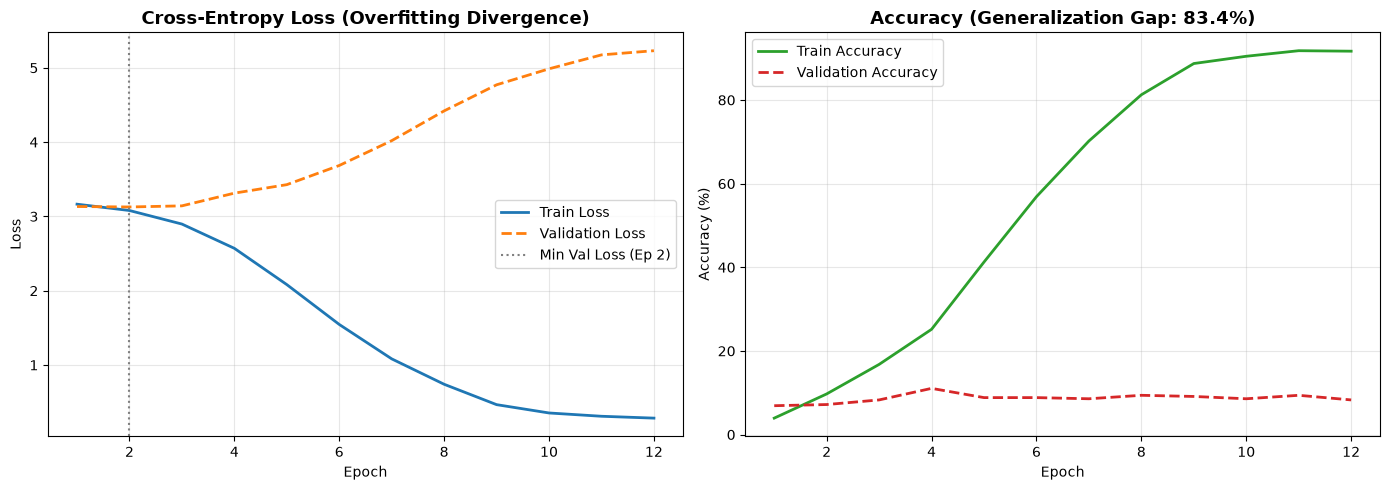

[Saved] c:\Users\jaxel\Desktop\COLLEGE\NLP\assignments\CV\models\overfitting_curves.png


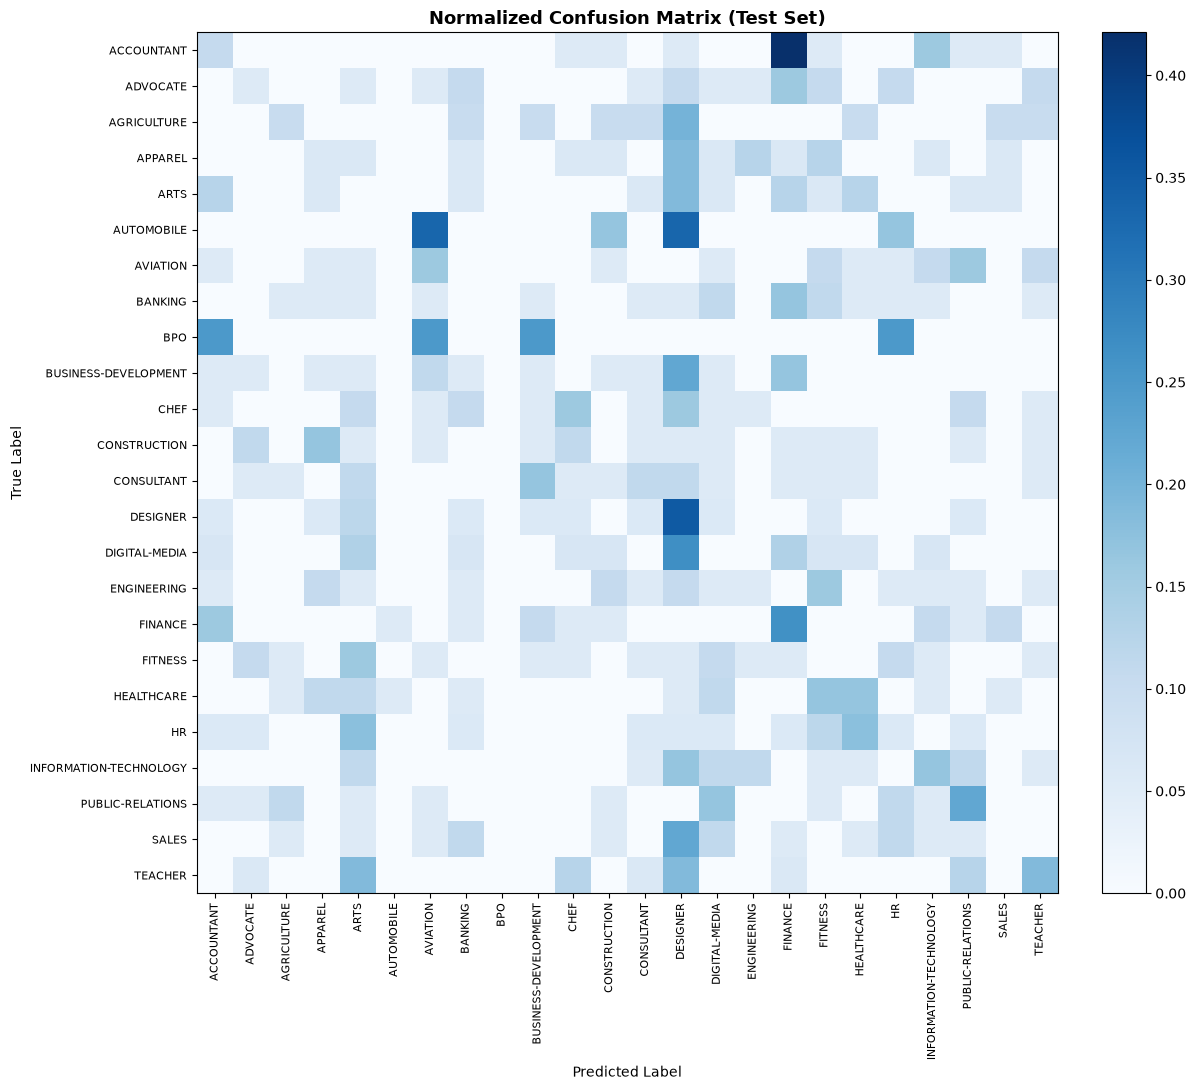

[Saved] c:\Users\jaxel\Desktop\COLLEGE\NLP\assignments\CV\models\confusion_matrix.png
[Saved] c:\Users\jaxel\Desktop\COLLEGE\NLP\assignments\CV\models\baseline_metrics.json


In [32]:
curves_path  = os.path.join(config.MODELS_DIR, "overfitting_curves.png")
cm_path      = os.path.join(config.MODELS_DIR, "confusion_matrix.png")
metrics_path = os.path.join(config.MODELS_DIR, "baseline_metrics.json")

plot_training_curves(history, curves_path)
cm = confusion_matrix(all_targets, all_preds, labels=range(len(class_names)))
plot_confusion_matrix(cm, class_names, cm_path)

summary_metrics = {
    "model_type": "Vanilla LSTM",
    "num_parameters": model.count_parameters()["total"],
    "epochs_trained": checkpoint["epoch"],
    "train_loss": checkpoint["final_train_loss"],
    "train_accuracy": checkpoint["final_train_acc"],
    "val_loss": checkpoint["final_val_loss"],
    "val_accuracy": checkpoint["final_val_acc"],
    "best_val_loss": checkpoint["best_val_loss"],
    "best_val_epoch": checkpoint["best_val_epoch"],
    "test_loss": test_loss,
    "test_accuracy": test_acc,
    "test_macro_f1": test_f1,
    "test_macro_precision": test_prec,
    "test_macro_recall": test_rec,
    "generalization_gap_acc": (checkpoint["final_train_acc"] - checkpoint["final_val_acc"]) * 100,
}
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(summary_metrics, f, indent=2)
print("[Saved]", metrics_path)